# Exercise 9: The Summer Swell Impact Analysis
**Team:** Swiss Quant Industrial

This notebook audits the late-August heatwave data and runs the actual Exercise 7 model on it. The task is not to retrain the model; the task is to show what changed, quantify the financial impact, and explain why the deployed logic collapses.

Labels use the final project convention: `0 = BAD`, `1 = GOOD`.


In [1]:
from pathlib import Path
import re
import sys
import warnings

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Markdown, display
from sklearn.metrics import accuracy_score, average_precision_score, confusion_matrix, precision_score, recall_score, roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict, train_test_split
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.utils.validation import check_is_fitted
import xgboost as xgb

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="talk")
pd.set_option("display.max_columns", 140)
pd.set_option("display.max_rows", 180)

BASE_DIR = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
DATA_DIR_150825 = BASE_DIR / "data" / "DataDump_150825"
DATA_DIR_300825 = BASE_DIR / "data" / "DataDump_300825"
OUTPUT_DIR = BASE_DIR / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)

BAD_CLASS = 0
GOOD_CLASS = 1
LABEL_NAMES = {BAD_CLASS: "BAD", GOOD_CLASS: "GOOD"}
RAW_TO_SEMANTIC_LABEL = {0: GOOD_CLASS, 1: BAD_CLASS}
BAD_SHIPPED_COST_CHF = 500
GOOD_WASTED_COST_CHF = 10

def feature_columns(df):
    return sorted([c for c in df.columns if c.startswith("feature_")], key=lambda c: int(c.split("_")[1]))

def standardize_manual_label(df, label_col="Manual_Label", raw_label_col="Manual_Label_Raw"):
    out = df.copy()
    raw = pd.to_numeric(out[label_col], errors="coerce")
    out[raw_label_col] = raw
    out[label_col] = raw.map(RAW_TO_SEMANTIC_LABEL).astype("Int64")
    return out

def add_label_name(df, label_col="Manual_Label"):
    out = df.copy()
    out[f"{label_col}_Name"] = out[label_col].map(LABEL_NAMES)
    return out

def load_master_table():
    df = pd.read_csv(OUTPUT_DIR / "exercise3_master_table_case_level.csv")
    if "Manual_Label" in df.columns:
        df["Manual_Label"] = pd.to_numeric(df["Manual_Label"], errors="coerce").astype("Int64")
    return df

def load_logbook_events():
    return pd.read_csv(OUTPUT_DIR / "logbook_events_structured.csv")

def load_heatwave_table():
    sensor = pd.read_csv(DATA_DIR_300825 / "sensor_data_august_shift.csv")
    quality = pd.read_csv(DATA_DIR_300825 / "quality_labels_august_shift.csv")
    production = pd.read_csv(DATA_DIR_300825 / "production_log_august_shift.csv", parse_dates=["Timestamp"])
    if len(sensor) != len(production):
        raise ValueError("Heatwave sensor and production logs should be row-aligned and equal length.")
    if not sensor["Charge_ID"].reset_index(drop=True).eq(production["Charge_ID"].reset_index(drop=True)).all():
        raise ValueError("Heatwave production rows are not row-aligned with sensor Charge_ID values.")
    table = sensor.merge(quality[["Case_ID", "Manual_Label", "Hash_Validation", "Legacy_Quality_Score"]], on="Case_ID", how="inner")
    if len(table) != len(sensor):
        raise ValueError("Heatwave quality merge changed row count; expected one label per Case_ID.")
    table = pd.concat([table.reset_index(drop=True), production.reset_index(drop=True)[["Timestamp", "Operator_ID"]]], axis=1)
    table = standardize_manual_label(table)
    table["label_available"] = table["Manual_Label"].notna()
    ts = pd.to_datetime(table["Timestamp"], errors="coerce")
    table["production_date"] = ts.dt.date
    table["production_hour"] = ts.dt.hour + ts.dt.minute / 60
    return add_label_name(table)

def _present_columns(df, cols):
    return [c for c in cols if c in df.columns]

def add_urs_rhythm_features(df, reference_df=None, source_features=("feature_2", "feature_4", "feature_5"), window=25):
    out = df.copy()
    signals = _present_columns(out, source_features)
    if not signals:
        raise ValueError("None of the rhythm source features are present.")
    reference = reference_df if reference_df is not None else out
    ref_numeric = reference[signals].apply(pd.to_numeric, errors="coerce")
    medians = ref_numeric.median()
    scales = ref_numeric.std().replace(0, np.nan).fillna(1.0)
    numeric = out[signals].apply(pd.to_numeric, errors="coerce").fillna(medians)
    standardized = (numeric - medians) / scales
    sort_cols = _present_columns(out, ["Timestamp_fixed", "Timestamp", "Charge_ID", "Case_ID"])
    ordered_index = out.sort_values(sort_cols).index if sort_cols else out.index
    ordered = standardized.loc[ordered_index]
    local_change = ordered.diff().abs().mean(axis=1).fillna(0.0)
    rolling_volatility = ordered.rolling(window=window, min_periods=3).std().mean(axis=1).fillna(0.0)
    rhythm = 0.4 * local_change + 0.6 * rolling_volatility
    out["Urs_Local_Signal_Change"] = local_change.reindex(out.index).astype(float)
    out["Urs_Rolling_Signal_Volatility"] = rolling_volatility.reindex(out.index).astype(float)
    out["Urs_Rhythm_Index"] = rhythm.reindex(out.index).astype(float)
    return out

def confusion_counts(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred, labels=[BAD_CLASS, GOOD_CLASS])
    return {
        "bad_correct": int(cm[0, 0]),
        "bad_shipped": int(cm[0, 1]),
        "good_wasted": int(cm[1, 0]),
        "good_correct": int(cm[1, 1]),
    }

def production_cost_chf(y_true, y_pred):
    counts = confusion_counts(y_true, y_pred)
    return counts["bad_shipped"] * BAD_SHIPPED_COST_CHF + counts["good_wasted"] * GOOD_WASTED_COST_CHF

def classification_summary(y_true, y_pred, model, threshold=None):
    counts = confusion_counts(y_true, y_pred)
    return {
        "model": model,
        "threshold": threshold,
        "rows": len(y_true),
        **counts,
        "bad_shipped_cost_chf": counts["bad_shipped"] * BAD_SHIPPED_COST_CHF,
        "good_wasted_cost_chf": counts["good_wasted"] * GOOD_WASTED_COST_CHF,
        "cost_chf": production_cost_chf(y_true, y_pred),
        "accuracy": accuracy_score(y_true, y_pred),
        "precision_bad": precision_score(y_true, y_pred, pos_label=BAD_CLASS, zero_division=0),
        "recall_bad": recall_score(y_true, y_pred, pos_label=BAD_CLASS, zero_division=0),
        "precision_good": precision_score(y_true, y_pred, pos_label=GOOD_CLASS, zero_division=0),
        "recall_good": recall_score(y_true, y_pred, pos_label=GOOD_CLASS, zero_division=0),
    }

def confusion_frame(y_true, y_pred):
    return pd.DataFrame(
        confusion_matrix(y_true, y_pred, labels=[BAD_CLASS, GOOD_CLASS]),
        index=["Actual BAD (0)", "Actual GOOD (1)"],
        columns=["Pred BAD (0)", "Pred GOOD (1)"],
    )

def predict_from_bad_probability(prob_bad, threshold):
    return pd.Series(np.where(np.asarray(prob_bad) >= threshold, BAD_CLASS, GOOD_CLASS))


## 1. Build the Real Heatwave Case Table

The late-August production log is row-aligned with the sensor file. We therefore attach production context by row order instead of joining by `Charge_ID`, because `Charge_ID` repeats and would otherwise create duplicate rows. The final impact table has exactly 150 heatwave cases.


In [2]:
master = load_master_table()
master_labeled = master.dropna(subset=["Manual_Label"]).copy()
master_labeled["Manual_Label"] = master_labeled["Manual_Label"].astype(int)
master_with_rhythm = add_urs_rhythm_features(master_labeled)

heatwave = load_heatwave_table()
heatwave = add_urs_rhythm_features(heatwave, reference_df=master_labeled)
heatwave["Manual_Label"] = heatwave["Manual_Label"].astype(int)
if len(heatwave) != 150:
    raise AssertionError(f"Expected 150 heatwave rows, found {len(heatwave)}")

heatwave_start = pd.to_datetime(heatwave["Timestamp"]).min()
heatwave_end = pd.to_datetime(heatwave["Timestamp"]).max()
heatwave_hours = (heatwave_end - heatwave_start).total_seconds() / 3600

label_audit = pd.DataFrame([
    {"dataset": "early-August training period", "BAD rows (0)": int((master_labeled["Manual_Label"] == BAD_CLASS).sum()), "GOOD rows (1)": int((master_labeled["Manual_Label"] == GOOD_CLASS).sum()), "rows": len(master_labeled)},
    {"dataset": "late-August heatwave period", "BAD rows (0)": int((heatwave["Manual_Label"] == BAD_CLASS).sum()), "GOOD rows (1)": int((heatwave["Manual_Label"] == GOOD_CLASS).sum()), "rows": len(heatwave)},
])
display(label_audit)
display(Markdown(f"Heatwave table covers **{len(heatwave)} cases** from **{heatwave_start}** to **{heatwave_end}** ({heatwave_hours:.1f} hours)."))
display(heatwave.head())


,dataset,BAD rows (0),GOOD rows (1),rows
0,early-August training period,722,682,1404
1,late-August heatwave period,15,135,150


Heatwave table covers **150 cases** from **2025-08-25 04:51:59.194630872** to **2025-08-28 20:49:00** (88.0 hours).

,Case_ID,Charge_ID,feature_1,feature_3,feature_5,feature_6,feature_7,feature_8,feature_9,feature_10,feature_11,feature_12,feature_13,feature_14,feature_15,feature_16,feature_17,feature_18,feature_19,feature_20,feature_21,feature_22,feature_23,feature_24,feature_25,feature_26,feature_27,feature_28,feature_29,feature_30,feature_31,feature_32,feature_33,feature_4,feature_2,Manual_Label,Hash_Validation,Legacy_Quality_Score,Timestamp,Operator_ID,Manual_Label_Raw,label_available,production_date,production_hour,Manual_Label_Name,Urs_Local_Signal_Change,Urs_Rolling_Signal_Volatility,Urs_Rhythm_Index
0,13007,118,16.0,9,13,0,16,0,29,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,-3,0,5,5,106,-23.0,83,203,701.998797,1,1e62b9cd,0.602526,2025-08-25 17:07:00.000000000,8266,0,True,2025-08-25,17.116667,GOOD,0.175073,0.733141,0.509914
1,13008,196,17.0,16,13,0,1,0,29,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,2,4,160,-27.0,1,161,1336.694652,1,3f1e355b,0.071323,2025-08-25 20:10:59.597315436,9266,0,True,2025-08-25,20.166667,GOOD,0.916119,0.775579,0.831795
2,13009,165,43.0,17,13,0,11,0,48,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,8,10,116,27.0,1,200,463.804433,1,ded65914,0.069230,2025-08-25 04:51:59.194630872,4818,0,True,2025-08-25,4.850000,GOOD,0.000000,0.000000,0.000000
3,13010,178,14.0,18,27,0,1,0,5,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,2,149,-34.0,7,214,384.944465,1,cb78bb73,0.210387,2025-08-25 17:40:58.791946308,8266,0,True,2025-08-25,17.666667,GOOD,0.567063,0.714451,0.655496
4,13011,185,50.0,14,12,0,2,0,6,0,4,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,3,1,57,-23.0,117,91,10.000000,1,a6ac2f15,0.290295,2025-08-25 14:11:58.389261744,9266,0,True,2025-08-25,14.183333,GOOD,1.314485,0.793255,1.001747


## 2. Data Audit: What Changed?

The table compares early-August labeled data against late-August heatwave data. `standardized_mean_delta` reports the heatwave mean shift in units of the early-August standard deviation. Values near zero mean stable; large positive or negative values mean the model is seeing a different operating regime than the one it learned from.

The density plots compare full distributions, not only averages. When the orange heatwave curve moves away from the blue early-August curve, the model receives inputs outside its familiar range. This is covariate shift. The GOOD-vs-GOOD audit then checks the business-critical claim: even genuinely GOOD heatwave peas look different from genuinely GOOD early-August peas.

,feature,early_mean,heatwave_mean,early_median,heatwave_median,early_std,heatwave_std,standardized_mean_delta,abs_standardized_delta,early_missing_pct,heatwave_missing_pct
0,Urs_Rhythm_Index,0.529061,0.994063,0.469752,0.947203,0.468605,0.288306,0.992310,0.992310,0.000000,0.0
1,Urs_Rolling_Signal_Volatility,0.540725,0.930349,0.530739,0.936856,0.410811,0.179604,0.948426,0.948426,0.000000,0.0
2,Urs_Local_Signal_Change,0.511566,1.089635,0.216248,0.994514,0.694396,0.585889,0.832477,0.832477,0.000000,0.0
3,feature_4,109.274217,159.946667,57.000000,162.500000,80.862067,81.112796,0.626653,0.626653,0.000000,0.0
4,feature_2,565.347934,736.842446,360.500000,719.808071,528.938986,494.222469,0.324224,0.324224,0.138177,0.0
5,feature_3,21.413818,20.386667,17.000000,16.500000,10.130389,9.867435,-0.101393,0.101393,0.000000,0.0
6,feature_29,3.685897,3.433333,3.000000,3.000000,2.507363,2.372710,-0.100729,0.100729,0.000000,0.0
7,feature_10,0.326923,0.000000,0.000000,0.000000,3.659700,0.000000,-0.089331,0.089331,0.000000,0.0
8,feature_11,1.234330,1.520000,0.000000,0.000000,3.285631,3.717761,0.086945,0.086945,0.000000,0.0
9,feature_9,23.896011,22.913333,14.000000,13.000000,23.269024,19.406266,-0.042231,0.042231,0.000000,0.0


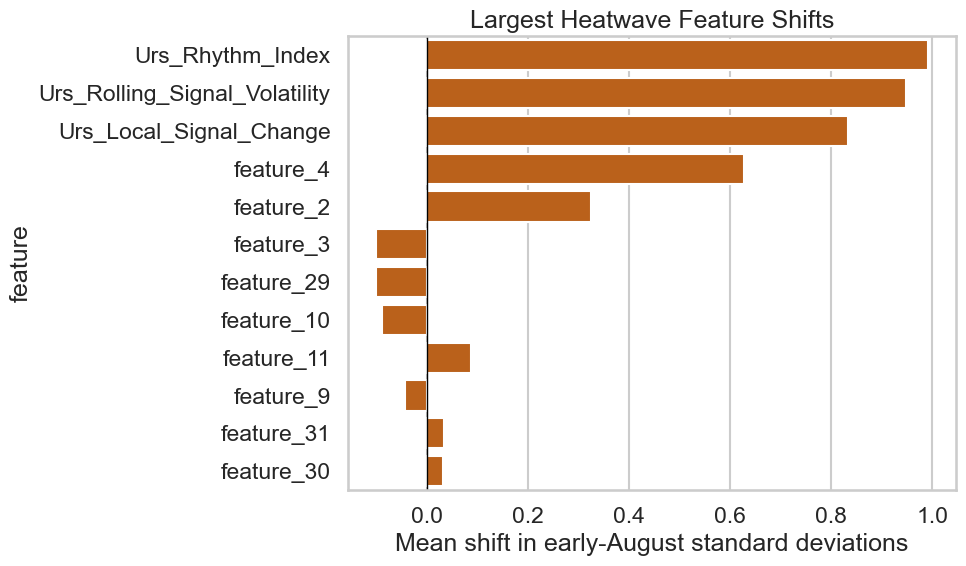

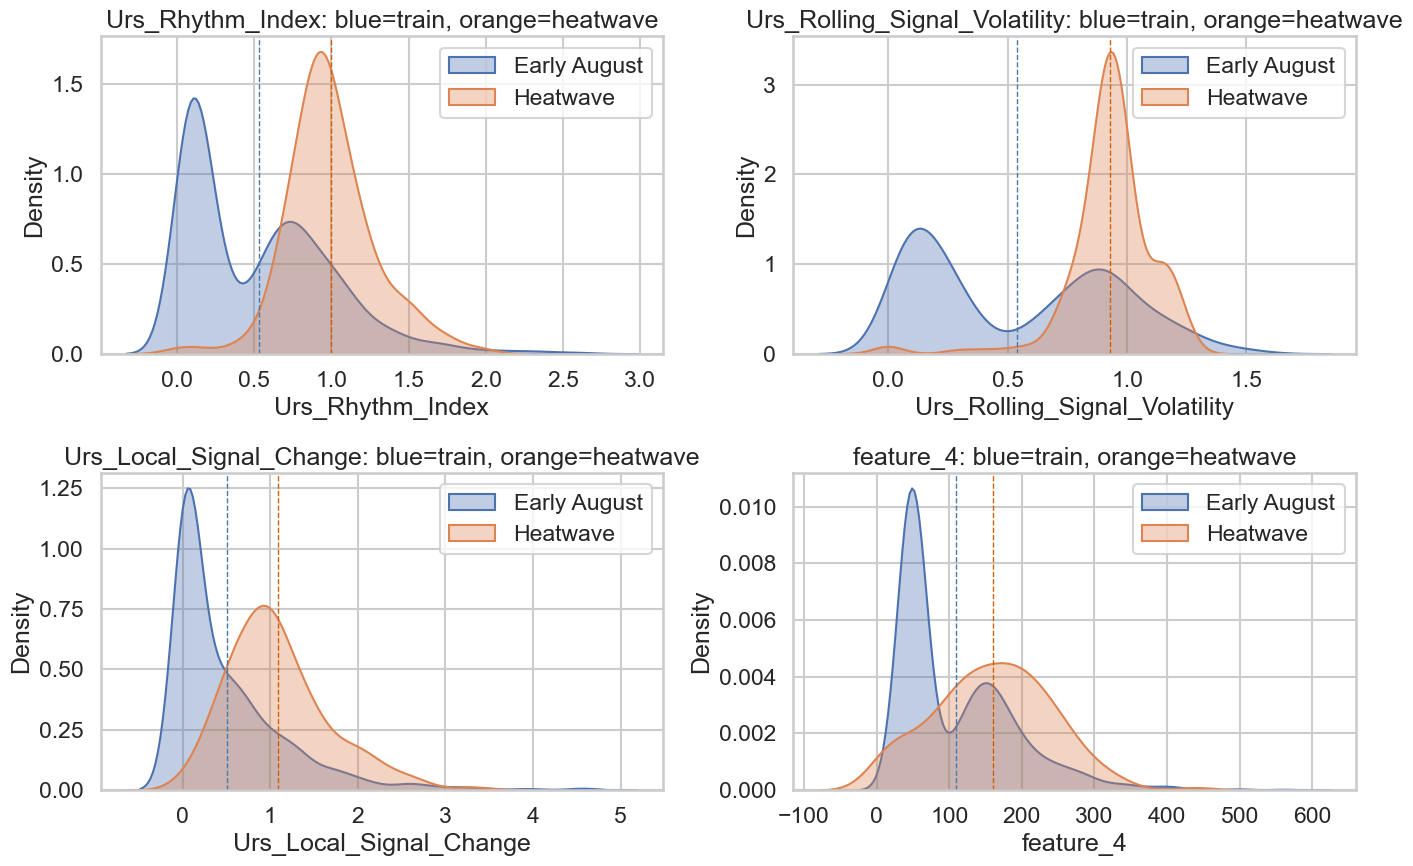

,feature,interpretation
0,Urs_Rhythm_Index,Heatwave distribution shifted materially; moni...
1,Urs_Rolling_Signal_Volatility,Heatwave distribution shifted materially; moni...
2,Urs_Local_Signal_Change,Heatwave distribution shifted materially; moni...
3,feature_4,Heatwave distribution shifted materially; moni...
4,feature_2,Distribution is comparatively stable; less lik...
5,feature_3,Distribution is comparatively stable; less lik...
6,feature_29,Distribution is comparatively stable; less lik...
7,feature_10,Distribution is comparatively stable; less lik...


**GOOD-vs-GOOD drift check:** the table below compares only confirmed GOOD early-August cases with confirmed GOOD heatwave cases. This isolates the Summer Swell effect from a change in defect prevalence.

,feature,early_good_mean,heatwave_good_mean,early_good_median,heatwave_good_median,standardized_good_mean_delta,abs_standardized_good_delta
0,feature_31,136.589443,107.237037,142.000000,105.000000,-0.863366,0.863366
1,feature_32,-43.606000,-10.451852,-34.000000,10.000000,0.732631,0.732631
2,feature_1,61.840198,39.651852,59.000000,20.000000,-0.716966,0.716966
3,feature_33,39.693548,21.222222,36.000000,4.000000,-0.681974,0.681974
4,feature_3,27.206745,20.392593,26.000000,17.000000,-0.631839,0.631839
5,feature_7,11.288856,6.681481,10.000000,4.000000,-0.561705,0.561705
6,feature_9,36.136364,22.748148,31.000000,13.000000,-0.528995,0.528995
7,feature_5,30.755132,22.718519,27.000000,13.000000,-0.518856,0.518856
8,feature_29,4.856305,3.585185,4.000000,3.000000,-0.487183,0.487183
9,Urs_Rhythm_Index,0.826323,0.991790,0.786353,0.946403,0.388420,0.388420


In [3]:
audit_features = [c for c in feature_columns(master_labeled) if c in heatwave.columns] + ["Urs_Local_Signal_Change", "Urs_Rolling_Signal_Volatility", "Urs_Rhythm_Index"]
drift_rows = []
for col in audit_features:
    old = pd.to_numeric(master_with_rhythm[col], errors="coerce")
    new = pd.to_numeric(heatwave[col], errors="coerce")
    old_std = old.std()
    standardized_delta = (new.mean() - old.mean()) / old_std if pd.notna(old_std) and old_std != 0 else np.nan
    drift_rows.append({"feature": col, "early_mean": old.mean(), "heatwave_mean": new.mean(), "early_median": old.median(), "heatwave_median": new.median(), "early_std": old_std, "heatwave_std": new.std(), "standardized_mean_delta": standardized_delta, "abs_standardized_delta": abs(standardized_delta) if pd.notna(standardized_delta) else np.nan, "early_missing_pct": old.isna().mean(), "heatwave_missing_pct": new.isna().mean()})

drift_audit = pd.DataFrame(drift_rows).sort_values("abs_standardized_delta", ascending=False).reset_index(drop=True)
drift_audit.to_csv(OUTPUT_DIR / "exercise9_drift_audit.csv", index=False)
display(drift_audit.head(15))

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(data=drift_audit.head(12), y="feature", x="standardized_mean_delta", color="#d55e00", ax=ax)
ax.axvline(0, color="black", linewidth=1)
ax.set_title("Largest Heatwave Feature Shifts")
ax.set_xlabel("Mean shift in early-August standard deviations")
plt.tight_layout()
plt.show()

top_shifted = drift_audit.head(4)["feature"].tolist()
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, col in zip(axes.ravel(), top_shifted):
    old = pd.to_numeric(master_with_rhythm[col], errors="coerce")
    new = pd.to_numeric(heatwave[col], errors="coerce")
    sns.kdeplot(old, label="Early August", fill=True, alpha=0.35, ax=ax)
    sns.kdeplot(new, label="Heatwave", fill=True, alpha=0.35, ax=ax)
    ax.axvline(old.mean(), color="#4c78a8", linestyle="--", linewidth=1)
    ax.axvline(new.mean(), color="#d55e00", linestyle="--", linewidth=1)
    ax.set_title(f"{col}: blue=train, orange=heatwave")
    ax.legend()
plt.tight_layout()
plt.show()

density_explanation = pd.DataFrame([
    {"feature": row.feature, "interpretation": "Heatwave distribution shifted materially; monitor and recalibrate before trusting the old decision boundary." if row.abs_standardized_delta >= 0.5 else "Distribution is comparatively stable; less likely to explain the failure alone."}
    for row in drift_audit.head(8).itertuples()
])
display(density_explanation)


early_good = master_with_rhythm.loc[master_with_rhythm["Manual_Label"].eq(GOOD_CLASS)].copy()
heatwave_good = heatwave.loc[heatwave["Manual_Label"].eq(GOOD_CLASS)].copy()
good_shift_rows = []
for col in audit_features:
    old = pd.to_numeric(early_good[col], errors="coerce")
    new = pd.to_numeric(heatwave_good[col], errors="coerce")
    old_std = old.std()
    standardized_delta = (new.mean() - old.mean()) / old_std if pd.notna(old_std) and old_std != 0 else np.nan
    good_shift_rows.append({
        "feature": col,
        "early_good_mean": old.mean(),
        "heatwave_good_mean": new.mean(),
        "early_good_median": old.median(),
        "heatwave_good_median": new.median(),
        "standardized_good_mean_delta": standardized_delta,
        "abs_standardized_good_delta": abs(standardized_delta) if pd.notna(standardized_delta) else np.nan,
    })

good_case_drift = pd.DataFrame(good_shift_rows).sort_values("abs_standardized_good_delta", ascending=False).reset_index(drop=True)
good_case_drift.to_csv(OUTPUT_DIR / "exercise9_good_case_drift_audit.csv", index=False)
display(Markdown("**GOOD-vs-GOOD drift check:** the table below compares only confirmed GOOD early-August cases with confirmed GOOD heatwave cases. This isolates the Summer Swell effect from a change in defect prevalence."))
display(good_case_drift.head(12))


## 3. Run the Exercise 7 Model on the Heatwave Period

The model handoff from Exercise 7 contains the trained XGBoost model, the validation-selected threshold, and the exact feature list. We apply it unchanged to the 150 heatwave cases, as requested.


Model threshold from Exercise 7: `0.049257`. Actual BAD rate: **10.0%**; model reject/BAD rate: **99.3%**.

,model,rows,bad_shipped,good_wasted,cost_chf,accuracy,precision_bad,recall_bad,precision_good,recall_good
0,Exercise 7 model on heatwave,150,0,134,1340,0.106667,0.100671,1.0,1.0,0.007407


,Pred BAD (0),Pred GOOD (1)
Actual BAD (0),15,0
Actual GOOD (1),134,1


,error_type,rows
0,GOOD wasted as BAD,134
1,Correct,16


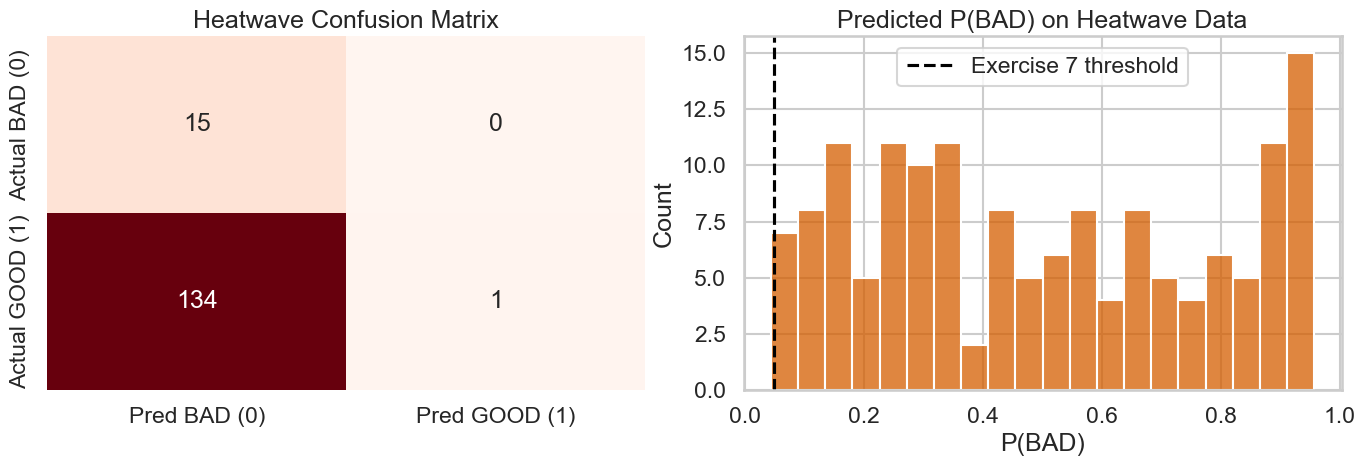

In [4]:
artifact = joblib.load(OUTPUT_DIR / "exercise7_model_artifact.joblib")
model = artifact["model"]
threshold = float(artifact["threshold"])
model_features = artifact["feature_columns"]

X_heatwave = heatwave.reindex(columns=model_features).apply(pd.to_numeric, errors="coerce")
y_true = heatwave["Manual_Label"].astype(int)
prob_bad = model.predict_proba(X_heatwave)[:, 1]
y_pred = predict_from_bad_probability(prob_bad, threshold)
y_pred.index = heatwave.index

impact = pd.DataFrame([classification_summary(y_true, y_pred, "Exercise 7 model on heatwave", threshold)])
cm = confusion_frame(y_true, y_pred)
reject_rate = float((y_pred == BAD_CLASS).mean())
actual_bad_rate = float((y_true == BAD_CLASS).mean())

predictions = heatwave[["Case_ID", "Charge_ID", "Manual_Label", "Manual_Label_Name", "Manual_Label_Raw", "Timestamp", "Operator_ID"]].copy()
predictions["pred_label"] = y_pred.astype(int)
predictions["pred_label_name"] = predictions["pred_label"].map(LABEL_NAMES)
predictions["prob_bad"] = prob_bad
predictions["threshold"] = threshold
predictions["error_type"] = np.select([
    predictions["Manual_Label"].eq(BAD_CLASS) & predictions["pred_label"].eq(GOOD_CLASS),
    predictions["Manual_Label"].eq(GOOD_CLASS) & predictions["pred_label"].eq(BAD_CLASS),
    predictions["Manual_Label"].eq(predictions["pred_label"]),
], ["BAD shipped as GOOD", "GOOD wasted as BAD", "Correct"], default="Unknown")
predictions.to_csv(OUTPUT_DIR / "exercise9_heatwave_predictions.csv", index=False)

display(Markdown(f"Model threshold from Exercise 7: `{threshold:.6f}`. Actual BAD rate: **{actual_bad_rate:.1%}**; model reject/BAD rate: **{reject_rate:.1%}**."))
display(impact[["model", "rows", "bad_shipped", "good_wasted", "cost_chf", "accuracy", "precision_bad", "recall_bad", "precision_good", "recall_good"]])
display(cm)
display(predictions["error_type"].value_counts().rename_axis("error_type").reset_index(name="rows"))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Reds", cbar=False, ax=axes[0])
axes[0].set_title("Heatwave Confusion Matrix")
sns.histplot(prob_bad, bins=20, ax=axes[1], color="#d55e00")
axes[1].axvline(threshold, color="black", linestyle="--", label="Exercise 7 threshold")
axes[1].set_title("Predicted P(BAD) on Heatwave Data")
axes[1].set_xlabel("P(BAD)")
axes[1].legend()
plt.tight_layout()
plt.show()


## 4. Financial Impact and Plain-Language Explanation

The immediate financial loss is calculated for the observed 150-case heatwave period. To make the business risk easier to scale, the same error rate is also expressed per 1,000 cases and per production hour in this heatwave sample.


In [5]:
financial_loss = int(impact.loc[0, "cost_chf"])
loss_per_1000_cases = financial_loss / len(heatwave) * 1000
loss_per_hour = financial_loss / heatwave_hours if heatwave_hours > 0 else np.nan
worst_features = drift_audit.head(5)[["feature", "early_mean", "heatwave_mean", "standardized_mean_delta"]]

comparison_path = OUTPUT_DIR / "exercise7_model_comparison.csv"
comparison = pd.read_csv(comparison_path)
stable_row = comparison.loc[comparison["model"].eq("Exercise 7 XGBoost, cost-optimized")].iloc[0]
expected_heatwave_loss = stable_row["cost_per_1000_cases_chf"] / 1000 * len(heatwave)
excess_loss = financial_loss - expected_heatwave_loss
expected_vs_actual = pd.DataFrame([
    {"scenario": "Expected from Exercise 7 stable-period cost rate", "cases": len(heatwave), "loss_chf": expected_heatwave_loss},
    {"scenario": "Actual Exercise 7 model loss on heatwave data", "cases": len(heatwave), "loss_chf": financial_loss},
    {"scenario": "Excess loss during heatwave period", "cases": len(heatwave), "loss_chf": excess_loss},
])

business_impact = pd.DataFrame([
    {"time_frame": "observed heatwave sample", "cases": len(heatwave), "hours": heatwave_hours, "estimated_loss_chf": financial_loss},
    {"time_frame": "normalized per 1,000 cases", "cases": 1000, "hours": np.nan, "estimated_loss_chf": loss_per_1000_cases},
    {"time_frame": "normalized per production hour in sample", "cases": np.nan, "hours": 1, "estimated_loss_chf": loss_per_hour},
])

display(worst_features)
display(expected_vs_actual)
display(business_impact)
display(Markdown(
    f"During the **150-case heatwave period**, the unchanged Exercise 7 model creates an estimated **{financial_loss:,.0f} CHF** classification loss. "
    f"Based on the Exercise 7 stable-period cost rate, we would have expected about **{expected_heatwave_loss:,.0f} CHF** over 150 similar cases; the observed heatwave loss is **{excess_loss:,.0f} CHF higher**. "
    f"That equals roughly **{loss_per_1000_cases:,.0f} CHF per 1,000 cases** at the same error mix. "
    "The model did not become random; it applied the early-August boundary to a shifted late-August population and therefore rejected too many good cases."
))

,feature,early_mean,heatwave_mean,standardized_mean_delta
0,Urs_Rhythm_Index,0.529061,0.994063,0.992310
1,Urs_Rolling_Signal_Volatility,0.540725,0.930349,0.948426
2,Urs_Local_Signal_Change,0.511566,1.089635,0.832477
3,feature_4,109.274217,159.946667,0.626653
4,feature_2,565.347934,736.842446,0.324224


,scenario,cases,loss_chf
0,Expected from Exercise 7 stable-period cost rate,150,854.092527
1,Actual Exercise 7 model loss on heatwave data,150,1340.000000
2,Excess loss during heatwave period,150,485.907473


,time_frame,cases,hours,estimated_loss_chf
0,observed heatwave sample,150.0,87.950224,1340.000000
1,"normalized per 1,000 cases",1000.0,NaN,8933.333333
2,normalized per production hour in sample,NaN,1.000000,15.235891


During the **150-case heatwave period**, the unchanged Exercise 7 model creates an estimated **1,340 CHF** classification loss. Based on the Exercise 7 stable-period cost rate, we would have expected about **854 CHF** over 150 similar cases; the observed heatwave loss is **486 CHF higher**. That equals roughly **8,933 CHF per 1,000 cases** at the same error mix. The model did not become random; it applied the early-August boundary to a shifted late-August population and therefore rejected too many good cases.

## 5. Final Exercise 9 Answer

- **What changed?** The heatwave shifted several important covariates, especially the engineered rhythm/volatility measures and raw sorter features tied to appearance and process stability.
- **What changed for genuinely GOOD peas?** Confirmed GOOD heatwave peas also moved away from confirmed GOOD early-August peas, so the failure is not just a different defect rate; the physical definition of a normal good pea changed.
- **What happened to performance?** The unchanged Exercise 7 model became overly conservative on the heatwave population, rejecting almost everything as BAD.
- **Financial loss:** the notebook reports loss for the observed 150-case heatwave period, compares it with the stable-period expected loss for 150 cases, and normalizes it per 1,000 cases and per production hour.
- **Why did the logic collapse?** This is covariate shift: the relationship learned from early-August sensor ranges no longer matched late-August crop characteristics.
- **Model update:** none is performed here, because the exercise asks for impact analysis rather than retraining.